In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge

from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv("Housing.csv")

df.head()

print("Dataset Shape:", df.shape)

df.info()
df.head()

Dataset Shape: (545, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


#Exploratory Data Analysis (EDA)
Before building the model, I will first explore the dataset to understand the information it contains. I will check for missing values, review descriptive statistics, and examine the distribution of house prices. This will help me understand the data and identify anything that needs attention before training the model.

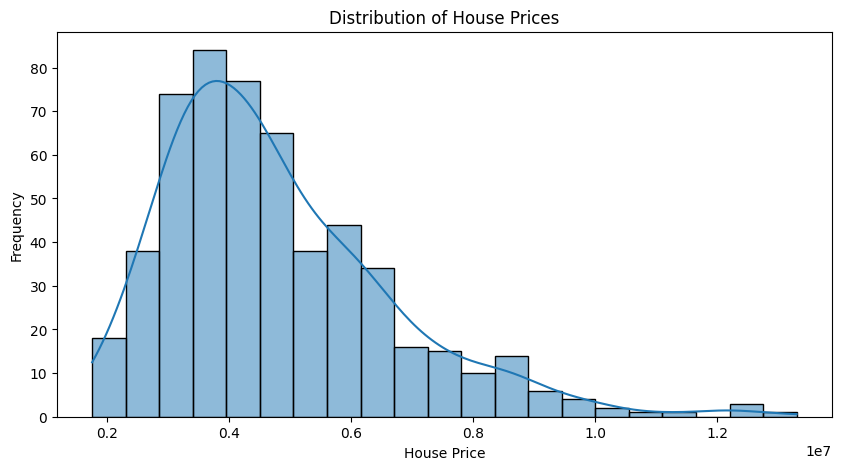

In [ ]:
df.isnull().sum()
df.describe()
plt.figure(figsize=(10, 5))

sns.histplot(df['price'], kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()

#Feature Selection Discussion
For this project, I selected features that are likely to influence house prices. These include the area of the property, number of bedrooms, bathrooms, stories, and parking spaces. I also selected features such as main road access, guestroom availability, basement, air conditioning, preferred area, and furnishing status.

I believe these features are useful because the size, location, facilities, and condition of a property can affect its selling price.

The dataset does not contain the exact age of houses or specific neighborhood names, so I will use the available location-related features, such as main road access and preferred area.

In [ ]:
X = df.drop('price', axis=1)

y = df['price']

print("Input Features:")
print(X.columns.tolist())

print("\nTarget Variable: price")

Input Features:
['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Target Variable: price


#Handle Missing Values and Encode Categorical Features (One-Hot Encoding)
The dataset contains both numerical and categorical features. Since Linear Regression requires numerical input, I will convert categorical features into numerical values using One-Hot Encoding.

I will also handle missing values by using the median for numerical columns and the most frequent value for categorical columns. I will apply these transformations through a preprocessing pipeline so that the training and testing data are handled consistently.

Numerical Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Categorical Features: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


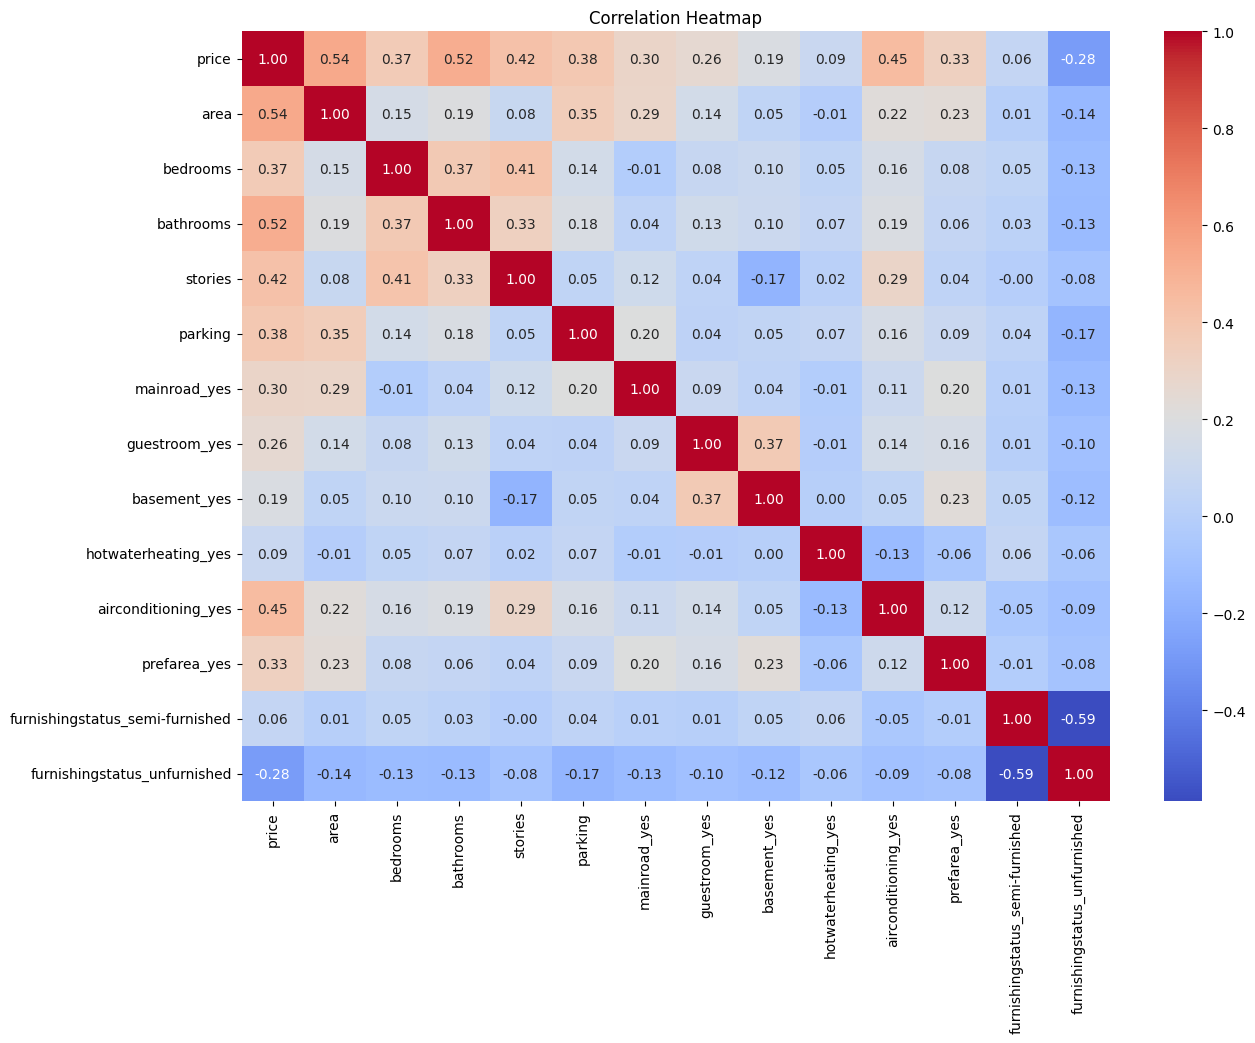

Training Data: (436, 12)
Testing Data: (109, 12)


In [ ]:
# Identify numerical and categorical features

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include='object'
).columns.tolist()

print("Numerical Features:", numeric_features)

print("Categorical Features:", categorical_features)


numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])


preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)


# Convert categorical columns into numerical columns

df_encoded = pd.get_dummies(
    df,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

# Calculate correlation

correlation = df_encoded.corr()

# Create heatmap

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()


correlation['price'].sort_values(ascending=False)


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

#Train Linear Regression Model
Linear Regression is a supervised machine learning algorithm used to predict continuous numerical values. In this project, I will train the model using house-related features to predict selling prices.

I will use the preprocessing pipeline together with Linear Regression so that the model receives properly prepared data during training and prediction.

In [ ]:
linear_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Train the model

linear_model.fit(X_train, y_train)


y_pred = linear_model.predict(X_test)

print("First 10 Predicted House Prices:")

print(y_pred[:10])

First 10 Predicted House Prices:
[5164653.90033967 7224722.29802166 3109863.24240338 4612075.32722559
 3294646.25725956 3532275.09556558 5611774.56836474 6368145.98732718
 2722856.95689986 2629405.61585783]


#Evaluate Model Using MSE, RMSE and R² Score
After training the model, I will evaluate its performance using three metrics.
- Mean Squared Error (MSE): Measures the average squared difference between actual and predicted prices. Lower values indicate smaller errors.
- Root Mean Squared Error (RMSE): Measures prediction errors in the same unit as house prices. Lower values are better.
- R² Score: Shows how much variation in house prices is explained by the model. A score closer to 1 generally indicates better performance.

Linear Regression Model Evaluation
----------------------------------
Mean Squared Error (MSE): 1754318687330.6682
Root Mean Squared Error (RMSE): 1324506.9600914402
R2 Score: 0.6529242642153175


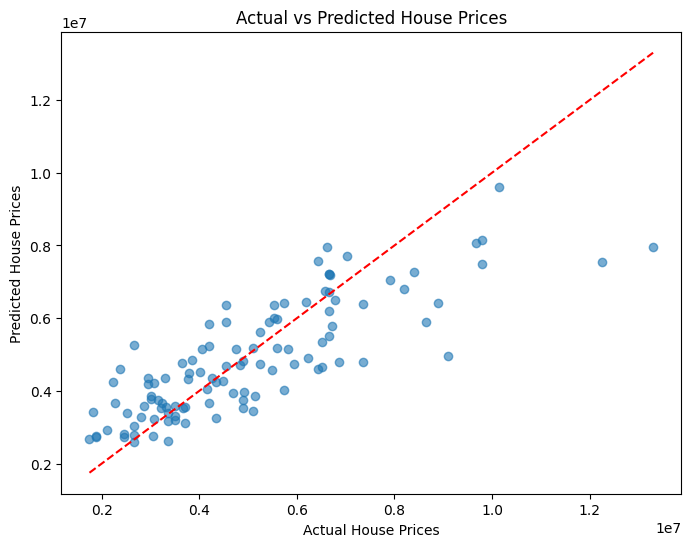

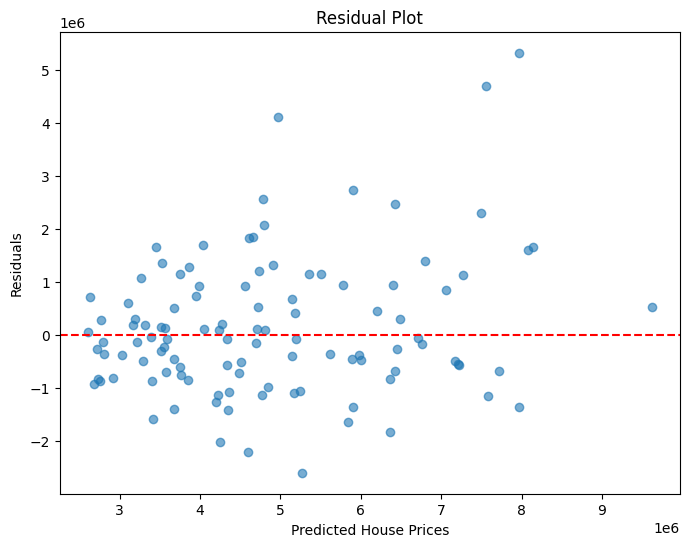

In [ ]:
# Calculate evaluation metrics

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results

print("Linear Regression Model Evaluation")
print("----------------------------------")

print("Mean Squared Error (MSE):", mse)

print("Root Mean Squared Error (RMSE):", rmse)

print("R2 Score:", r2)


plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

# Diagonal reference line

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual House Prices")

plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.show()


# Calculate residuals

residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.6
)

# Reference line at zero

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted House Prices")

plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()

#Coefficient Analysis
In Linear Regression, coefficients help me understand how different features are associated with predicted house prices.

Positive coefficients indicate that a feature is associated with an increase in predicted price, while negative coefficients indicate an association with a decrease in predicted price, keeping other features constant.

I will examine the coefficients to identify which features have the highest positive and negative impact on the model's predictions.

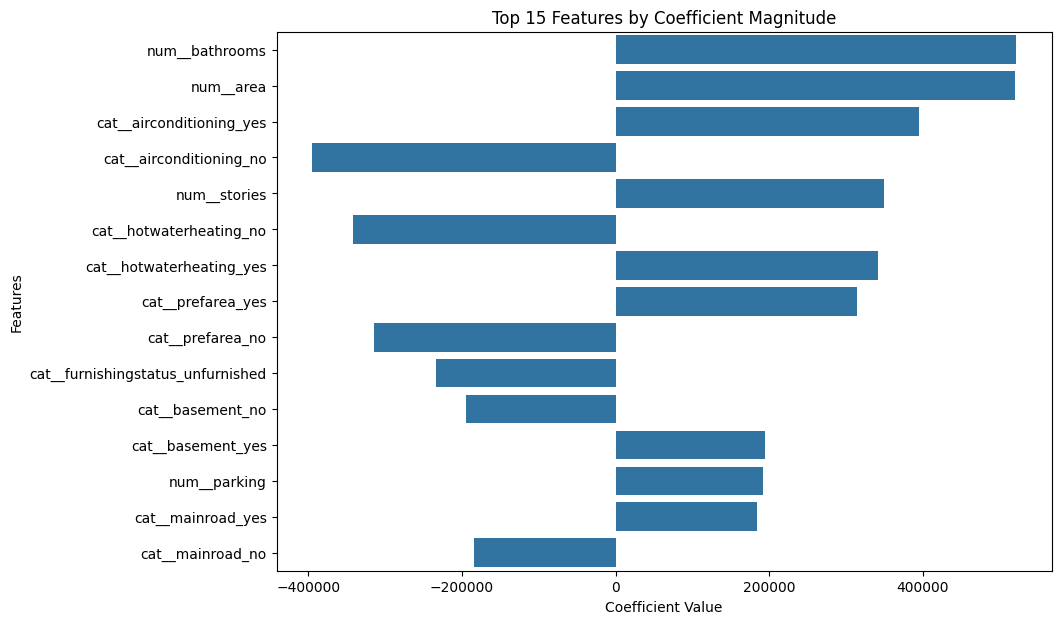

In [ ]:
# Get feature names after preprocessing

feature_names = linear_model.named_steps[
    'preprocessor'
].get_feature_names_out()

# Get coefficients

coefficients = linear_model.named_steps[
    'model'
].coef_

# Create coefficient DataFrame

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Sort by absolute coefficient values

coef_df['Absolute_Coefficient'] = (
    coef_df['Coefficient'].abs()
)

coef_df = coef_df.sort_values(
    by='Absolute_Coefficient',
    ascending=False
)

# Display all coefficients

coef_df


positive_impact = coef_df.sort_values(
    by='Coefficient',
    ascending=False
)

positive_impact.head(10)


negative_impact = coef_df.sort_values(
    by='Coefficient',
    ascending=True
)

negative_impact.head(10)


top_coefficients = coef_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_coefficients,
    x='Coefficient',
    y='Feature'
)

plt.title("Top 15 Features by Coefficient Magnitude")

plt.xlabel("Coefficient Value")

plt.ylabel("Features")

plt.show()

#Bonus – Compare Linear Regression with Ridge Regression
As an additional experiment, I will compare Linear Regression with Ridge Regression. Ridge Regression is a regularized version of Linear Regression that adds a penalty to large coefficients. This can help reduce overfitting and improve model stability.

I will train both models using the same training and testing data and compare their performance using MSE, RMSE, and R² Score.

In [ ]:
# Create Ridge Regression model

ridge_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=1.0))
])

# Train Ridge model

ridge_model.fit(X_train, y_train)

# Make predictions

ridge_pred = ridge_model.predict(X_test)


ridge_mse = mean_squared_error(y_test, ridge_pred)

ridge_rmse = np.sqrt(ridge_mse)

ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression Evaluation")
print("---------------------------")

print("MSE:", ridge_mse)

print("RMSE:", ridge_rmse)

print("R2 Score:", ridge_r2)


comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Ridge Regression'
    ],

    'MSE': [
        mse,
        ridge_mse
    ],

    'RMSE': [
        rmse,
        ridge_rmse
    ],

    'R2 Score': [
        r2,
        ridge_r2
    ]
})

comparison

Ridge Regression Evaluation
---------------------------
MSE: 1756731438876.3635
RMSE: 1325417.4583414705
R2 Score: 0.6524469236249018


,Model,MSE,RMSE,R2 Score
0,Linear Regression,1.754319e+12,1.324507e+06,0.652924
1,Ridge Regression,1.756731e+12,1.325417e+06,0.652447
